# **Cell 1 — Install dependencies**

In [ ]:
!pip -q install huggingface_hub scikit-learn scipy pandas numpy matplotlib seaborn joblib

# **Cell 2 — Download all four datasets**

In [ ]:
import os
import numpy as np
import pandas as pd

from huggingface_hub import hf_hub_download

REPO_ID = "FUMD-AI/krakow-handover-dataset"

RUNS = ["900_1", "1000_1", "1200_1", "1400_1"]

DATA = {}

for run in RUNS:

    print("Downloading:", run)

    path = hf_hub_download(
        repo_id=REPO_ID,
        filename=f"data/{run}/dataset_labeled_w3.csv",
        repo_type="dataset"
    )

    DATA[run] = path

    print("Downloaded:", path)

print("\nAll four datasets downloaded!")

Downloading: 900_1


data/900_1/dataset_labeled_w3.csv: reconstructing file:   0%|          |  0.00B / 55.9MB            

data/900_1/dataset_labeled_w3.csv: downloading bytes:           |  0.00B            

Downloaded: /root/.cache/huggingface/hub/datasets--FUMD-AI--krakow-handover-dataset/snapshots/5652090ebe1aa2f0742d4c28b2557fa87ca9d4f7/data/900_1/dataset_labeled_w3.csv
Downloading: 1000_1


data/1000_1/dataset_labeled_w3.csv: reconstructing file:   0%|          |  0.00B / 65.5MB            

data/1000_1/dataset_labeled_w3.csv: downloading bytes:           |  0.00B            

... (3 outputs left out)

Downloaded: /root/.cache/huggingface/hub/datasets--FUMD-AI--krakow-handover-dataset/snapshots/5652090ebe1aa2f0742d4c28b2557fa87ca9d4f7/data/1200_1/dataset_labeled_w3.csv
Downloading: 1400_1


data/1400_1/dataset_labeled_w3.csv: reconstructing file:   0%|          |  0.00B / 97.5MB            

data/1400_1/dataset_labeled_w3.csv: downloading bytes:           |  0.00B            

Downloaded: /root/.cache/huggingface/hub/datasets--FUMD-AI--krakow-handover-dataset/snapshots/5652090ebe1aa2f0742d4c28b2557fa87ca9d4f7/data/1400_1/dataset_labeled_w3.csv

All four datasets downloaded!


# **Cell 3 — Inspect the actual schema**

In [ ]:
sample = pd.read_csv(DATA["900_1"], nrows=10)

print("Number of columns:", len(sample.columns))

print("\nColumn names:")

for i, col in enumerate(sample.columns):
    print(i + 1, col)

print("\nData types:")
print(sample.dtypes)

display(sample.head())

Number of columns: 37

Column names:
1 t
2 veh_id
3 x
4 y
5 angle
6 speed
7 pos
8 lane
9 slope
10 signals
11 Time
12 Object
13 averageCqiDl
14 distance
15 measuredSinrDl
16 measuredSinrUl
17 rcvdSinrDl
18 rlcDelayDl
19 rlcPduDelayDl
20 rlcThroughputDl
21 servingCell
22 servingCell-1
23 servingCell1
24 servingCell-2
25 servingCell2
26 servingCell-3
27 servingCell3
28 servingCell-4
29 servingCell4
30 servingCell-5
31 servingCell5
32 servingCell-6
33 servingCell6
34 servingCell-7
35 servingCell7
36 migration
37 destination

Data types:
t                  float64
veh_id               int64
x                  float64
y                  float64
angle              float64
speed              float64
pos                float64
lane                object
slope              float64
signals            float64
Time               float64
Object               int64
averageCqiDl       float64
distance           float64
measuredSinrDl     float64
measuredSinrUl     float64
rcvdSinrDl         float64
rl

,t,veh_id,x,y,angle,speed,pos,lane,slope,signals,...,servingCell-4,servingCell4,servingCell-5,servingCell5,servingCell-6,servingCell6,servingCell-7,servingCell7,migration,destination
0,1.0,0,19.940037,50.055277,189.83,12.11,17.21,-94092847#1_0,0.0,0.0,...,-1,9,-1,9,-1,9,-1,9,0,9
1,2.0,0,19.940013,50.055178,189.83,11.16,28.37,-94092847#1_0,0.0,0.0,...,-1,9,-1,9,-1,9,-1,9,0,9
2,3.0,0,19.939986,50.055072,189.83,11.91,40.29,-94092847#1_0,0.0,0.0,...,-1,9,-1,9,-1,9,-1,9,0,9
3,4.0,0,19.939960,50.054964,189.85,12.16,8.87,:4069144706_0_0,0.0,0.0,...,-1,9,-1,9,-1,9,-1,9,0,9
4,5.0,0,19.939932,50.054858,191.30,11.92,11.39,-94092847#0_0,0.0,0.0,...,9,9,-1,9,-1,9,-1,9,0,9


In [ ]:
for run in RUNS:

    temp = pd.read_csv(DATA[run])

    print("\nRUN:", run)
    print("Shape:", temp.shape)
    print("Vehicles:", temp["veh_id"].nunique())

    print("\nMigration distribution:")
    print(temp["migration"].value_counts())

    del temp


RUN: 900_1
Shape: (259918, 37)
Vehicles: 775

Migration distribution:
migration
0    254184
2      3819
1      1915
Name: count, dtype: int64

RUN: 1000_1
Shape: (307879, 37)
Vehicles: 887

Migration distribution:
migration
0    301344
2      4352
1      2183
Name: count, dtype: int64

RUN: 1200_1
Shape: (373688, 37)
Vehicles: 1045

Migration distribution:
migration
0    365970
2      5136
1      2582
Name: count, dtype: int64

RUN: 1400_1
Shape: (466786, 37)
Vehicles: 1218

Migration distribution:
migration
0    458134
2      5758
1      2894
Name: count, dtype: int64


# **Cell 4 — Load all four runs**

In [ ]:
FEATURE_COLUMNS = [
    "t", "veh_id",

    # Mobility
    "x", "y", "angle", "speed", "pos", "signals",

    # Radio
    "averageCqiDl",
    "distance",
    "measuredSinrDl",
    "measuredSinrUl",
    "rcvdSinrDl",

    # Network performance
    "rlcDelayDl",
    "rlcPduDelayDl",
    "rlcThroughputDl",

    # Current and historical serving cells
    "servingCell",
    "servingCell-1",
    "servingCell-2",
    "servingCell-3",
    "servingCell-4",
    "servingCell-5",
    "servingCell-6",
    "servingCell-7",

    # Targets
    "migration",
    "destination"
]

frames = []

for run in RUNS:

    print("Loading:", run)

    temp = pd.read_csv(
        DATA[run],
        usecols=FEATURE_COLUMNS
    )

    temp["run_id"] = run

    # A vehicle ID is unique only within its own run
    temp["group_id"] = (
        run + "_" + temp["veh_id"].astype(str)
    )

    frames.append(temp)

df = pd.concat(
    frames,
    ignore_index=True
)

print("\nCombined dataset:", df.shape)

print("Total vehicles:",
      df["group_id"].nunique())

display(df.head())

Loading: 900_1
Loading: 1000_1
Loading: 1200_1
Loading: 1400_1

Combined dataset: (1408271, 28)
Total vehicles: 3925


,t,veh_id,x,y,angle,speed,pos,signals,averageCqiDl,distance,...,servingCell-2,servingCell-3,servingCell-4,servingCell-5,servingCell-6,servingCell-7,migration,destination,run_id,group_id
0,1.0,0,19.940037,50.055277,189.83,12.11,17.21,0.0,12.0,230.944709,...,-1,-1,-1,-1,-1,-1,0,9,900_1,900_1_0
1,2.0,0,19.940013,50.055178,189.83,11.16,28.37,0.0,12.0,232.978645,...,-1,-1,-1,-1,-1,-1,0,9,900_1,900_1_0
2,3.0,0,19.939986,50.055072,189.83,11.91,40.29,0.0,14.0,235.824775,...,9,-1,-1,-1,-1,-1,0,9,900_1,900_1_0
3,4.0,0,19.939960,50.054964,189.85,12.16,8.87,0.0,11.0,239.732928,...,9,9,-1,-1,-1,-1,0,9,900_1,900_1_0
4,5.0,0,19.939932,50.054858,191.30,11.92,11.39,0.0,13.0,244.252613,...,9,9,9,-1,-1,-1,0,9,900_1,900_1_0


# **Cell 5 — Validate the dataset**

In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nMigration distribution:")
display(df["migration"].value_counts().sort_index())

print("\nMigration percentage:")
display(
    df["migration"].value_counts(normalize=True).sort_index() * 100
)

print("\nDestination distribution:")
display(df["destination"].value_counts().sort_index())

print("\nServing cell distribution:")
display(df["servingCell"].value_counts().sort_index())

Dataset shape: (1408271, 28)

Missing values:
t                  0
veh_id             0
x                  0
y                  0
angle              0
speed              0
pos                0
signals            0
averageCqiDl       0
distance           0
measuredSinrDl     0
measuredSinrUl     0
rcvdSinrDl         0
rlcDelayDl         0
rlcPduDelayDl      0
rlcThroughputDl    0
servingCell        0
servingCell-1      0
servingCell-2      0
servingCell-3      0
servingCell-4      0
servingCell-5      0
servingCell-6      0
servingCell-7      0
migration          0
destination        0
run_id             0
group_id           0
dtype: int64

Migration distribution:


,count
migration,
0,1379632
1,9574
2,19065



Migration percentage:


,proportion
migration,
0,97.966372
1,0.679841
2,1.353788



Destination distribution:


,count
destination,
1,101020
2,171631
3,108594
4,75044
5,317159
6,105582
7,156118
8,81363
9,291760



Serving cell distribution:


,count
servingCell,
1,101424
2,171945
3,108185
4,75345
5,317046
6,105288
7,155618
8,81607
9,291813


# **Cell 6 — Visualize the dataset**

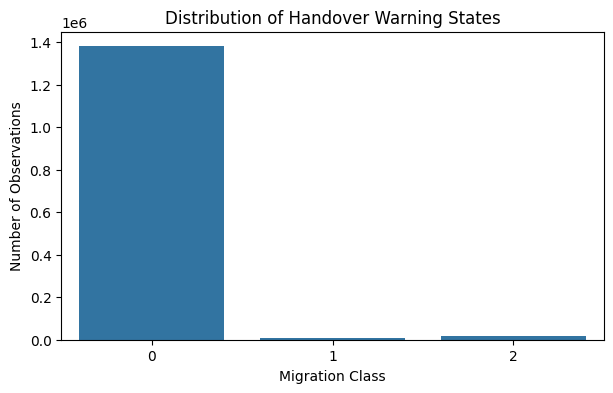

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="migration"
)

plt.title("Distribution of Handover Warning States")
plt.xlabel("Migration Class")
plt.ylabel("Number of Observations")

plt.show()

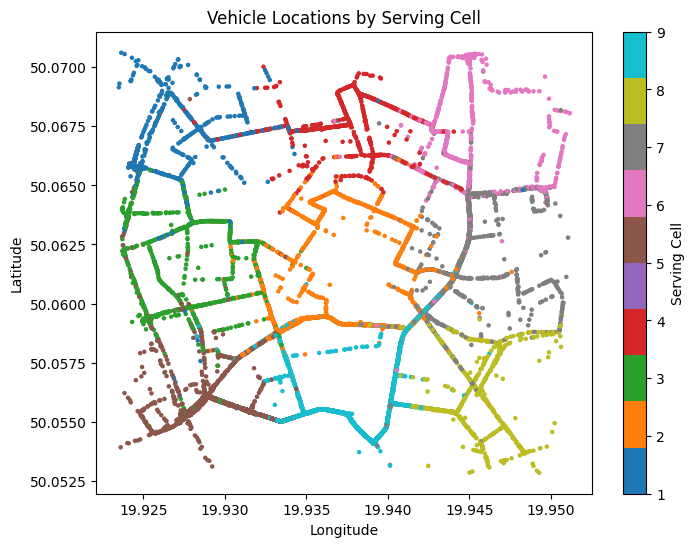

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["x"].iloc[::100],
    df["y"].iloc[::100],
    c=df["servingCell"].iloc[::100],
    cmap="tab10",
    s=5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Vehicle Locations by Serving Cell")

plt.colorbar(label="Serving Cell")

plt.show()

# **Cell 7 — Feature engineering**

In [ ]:

# ============================================================
# CELL 7: CHRONOLOGICAL SORTING AND FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd

# Sort each vehicle's observations chronologically
df = df.sort_values(
    ["group_id", "t"]
).reset_index(drop=True)

# Circular encoding of direction
df["angle_sin"] = np.sin(
    np.deg2rad(df["angle"])
)

df["angle_cos"] = np.cos(
    np.deg2rad(df["angle"])
)

print("Chronological sorting completed.")

# Check timestamp increments
time_diffs = (
    df.groupby("group_id")["t"]
      .diff()
      .dropna()
)

print("\nTimestamp difference statistics:")
print(time_diffs.describe())

print("\nMost common timestamp differences:")
print(time_diffs.value_counts().head(10))

print("\nNegative timestamp differences:",
      (time_diffs < 0).sum())

# Check whether timestamps are strictly increasing
assert (time_diffs >= 0).all()

print("\nSorting and angle encoding completed.")


Chronological sorting completed.

Timestamp difference statistics:
count    1.404346e+06
mean     1.000992e+00
std      1.441263e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      6.900000e+01
Name: t, dtype: float64

Most common timestamp differences:
t
1.0     1404145
2.0          49
3.0          28
4.0          23
5.0          17
7.0          15
6.0          15
8.0           8
12.0          5
9.0           5
Name: count, dtype: int64

Negative timestamp differences: 0

Sorting and angle encoding completed.


# **Cell 8 — Construct the feature matrix**

In [ ]:

# ============================================================
# CELL 8: FEATURE MATRIX
# ============================================================

NUMERIC_FEATURES = [
    "x",
    "y",
    "pos",
    "speed",
    "signals",
    "angle_sin",
    "angle_cos",
    "averageCqiDl",
    "distance",
    "measuredSinrDl",
    "measuredSinrUl",
    "rcvdSinrDl",
    "rlcDelayDl",
    "rlcPduDelayDl",
    "rlcThroughputDl"
]

CELL_FEATURES = [
    "servingCell",
    "servingCell-1",
    "servingCell-2",
    "servingCell-3"
]

# Numerical features
X_num = df[NUMERIC_FEATURES].copy()

# Categorical serving-cell features
X_cat = pd.DataFrame(index=df.index)

for col in CELL_FEATURES:
    X_cat[col] = df[col].astype(str)

X_cat = pd.get_dummies(
    X_cat,
    dtype=np.float32
)

# Combined feature matrix
X = pd.concat(
    [X_num, X_cat],
    axis=1
)

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.astype(np.float32)

print("Feature matrix:", X.shape)
print("Numerical features:", len(NUMERIC_FEATURES))
print("Categorical features:", len(X_cat.columns))

print("NaN values:", X.isna().sum().sum())
print("Infinite values:",
      np.isinf(X.select_dtypes(include=np.number)).sum().sum())

display(X.head())


Feature matrix: (1408271, 57)
Numerical features: 15
Categorical features: 42
NaN values: 0
Infinite values: 0


,x,y,pos,speed,signals,angle_sin,angle_cos,averageCqiDl,distance,measuredSinrDl,...,servingCell-3_0,servingCell-3_1,servingCell-3_2,servingCell-3_3,servingCell-3_4,servingCell-3_5,servingCell-3_6,servingCell-3_7,servingCell-3_8,servingCell-3_9
0,19.948133,50.053612,2.13,7.77,0.0,-0.941999,-0.335616,11.0,289.778656,21.287771,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,19.948034,50.053585,6.94,7.58,0.0,-0.940940,-0.338574,10.0,288.691711,19.665234,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,19.947927,50.053562,4.72,8.20,0.0,-0.940881,-0.338738,14.0,287.863617,34.643021,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,19.947834,50.053539,11.84,7.12,10.0,-0.940881,-0.338738,7.0,287.269928,11.544637,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,19.947735,50.053513,19.35,7.51,2.0,-0.940881,-0.338738,11.0,286.905762,22.452475,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# **Cell 9 — Construct both prediction targets**

In [ ]:
# ============================================================
# CELL 9: CONSTRUCT HANDOVER AND TEMPORAL PREDICTION TARGETS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# STEP 1: EXISTING CLASSIFICATION TARGETS
# ------------------------------------------------------------

# Binary handover warning prediction
y_handover = (
    df["migration"] > 0
).astype(np.int8)

# Destination cell prediction
y_destination = df["destination"].astype(np.int8)


# ------------------------------------------------------------
# STEP 2: CONFIGURATION
# ------------------------------------------------------------

# IMPORTANT:
# Use 1.0 only if t is measured in seconds.
# Use 0.001 if t is measured in milliseconds.
TIME_TO_SECONDS = 1.0

HORIZONS = [30, 60]


# ------------------------------------------------------------
# STEP 3: SORT CHRONOLOGICALLY
# ------------------------------------------------------------

df = df.sort_values(
    ["group_id", "t"]
).reset_index(drop=True)

# Convert timestamps into seconds
df["time_seconds"] = (
    df["t"].astype(float) * TIME_TO_SECONDS
)

# Check timestamp validity
assert df["time_seconds"].notna().all(), (
    "Timestamp column contains missing values."
)

# Initialize temporal target columns
df["handover_event"] = 0
df["cumulative_handovers"] = 0

for horizon in HORIZONS:
    df[f"past_count_{horizon}s"] = 0
    df[f"future_count_{horizon}s"] = np.nan


# ------------------------------------------------------------
# STEP 4: CONSTRUCT HANDOVER EVENTS
# ------------------------------------------------------------

for group_id, group in df.groupby(
    "group_id",
    sort=False
):

    idx = group.index.to_numpy()

    times = group["time_seconds"].to_numpy()
    serving = group["servingCell"].to_numpy()

    # --------------------------------------------------------
    # Detect serving-cell transitions
    # --------------------------------------------------------

    events = np.zeros(
        len(group),
        dtype=np.int8
    )

    if len(group) > 1:
        events[1:] = (
            serving[1:] != serving[:-1]
        ).astype(np.int8)

    # Store event indicators
    df.loc[idx, "handover_event"] = events

    # Times at which serving-cell transitions occur
    event_times = times[events == 1]

    # --------------------------------------------------------
    # Cumulative handover count
    # --------------------------------------------------------

    cumulative = np.cumsum(events)

    df.loc[
        idx,
        "cumulative_handovers"
    ] = cumulative

    # --------------------------------------------------------
    # Past and future handover counts
    # --------------------------------------------------------

    for horizon in HORIZONS:

        # ====================================================
        # PAST HANDOVERS
        # Window: (t - horizon, t]
        # ====================================================

        past_left = np.searchsorted(
            event_times,
            times - horizon,
            side="right"
        )

        past_right = np.searchsorted(
            event_times,
            times,
            side="right"
        )

        past_count = (
            past_right - past_left
        )

        df.loc[
            idx,
            f"past_count_{horizon}s"
        ] = past_count

        # ====================================================
        # FUTURE HANDOVERS
        # Window: (t, t + horizon]
        # ====================================================

        future_left = np.searchsorted(
            event_times,
            times,
            side="right"
        )

        future_right = np.searchsorted(
            event_times,
            times + horizon,
            side="right"
        )

        future_count = (
            future_right - future_left
        ).astype(float)

        # Exclude observations without a complete
        # future observation window
        valid = (
            times + horizon <= times[-1]
        )

        future_count[~valid] = np.nan

        df.loc[
            idx,
            f"future_count_{horizon}s"
        ] = future_count


# ------------------------------------------------------------
# STEP 5: HANDOVER RATE PER MINUTE
# ------------------------------------------------------------

# Number of handovers in the previous 60 seconds
# is equivalent to handovers per minute.

df["past_handover_rate"] = (
    df["past_count_60s"].astype(float)
)


# ------------------------------------------------------------
# STEP 6: SUMMARY AND VALIDATION
# ------------------------------------------------------------

print("=" * 60)
print("TEMPORAL HANDOVER TARGET CONSTRUCTION COMPLETED")
print("=" * 60)

print("\nBinary handover target:")
print(y_handover.value_counts())

print("\nDestination target:")
print(y_destination.value_counts())

print("\nHandover event distribution:")
print(df["handover_event"].value_counts())

print("\nCumulative handover statistics:")
print(df["cumulative_handovers"].describe())

print("\nPast handover count statistics:")

for horizon in HORIZONS:
    print(f"\nPast {horizon}-second count:")
    print(df[f"past_count_{horizon}s"].describe())

print("\nFuture handover count statistics:")

for horizon in HORIZONS:
    col = f"future_count_{horizon}s"

    print(f"\nFuture {horizon}-second count:")
    print(df[col].describe())

    print(
        "Valid observations:",
        df[col].notna().sum()
    )

    print(
        "Invalid observations:",
        df[col].isna().sum()
    )

print("\nPast handover rate per minute:")
print(df["past_handover_rate"].describe())


# ------------------------------------------------------------
# STEP 7: FINAL CHECKS
# ------------------------------------------------------------

assert (
    df["cumulative_handovers"] >= 0
).all()

assert (
    df["past_count_30s"] >= 0
).all()

assert (
    df["past_count_60s"] >= 0
).all()

assert (
    df["past_count_60s"] >= df["past_count_30s"]
).all()

print("\nAll temporal target checks passed.")

display(
    df[
        [
            "group_id",
            "t",
            "servingCell",
            "handover_event",
            "cumulative_handovers",
            "past_count_30s",
            "past_count_60s",
            "past_handover_rate",
            "future_count_30s",
            "future_count_60s"
        ]
    ].head(15)
)

TEMPORAL HANDOVER TARGET CONSTRUCTION COMPLETED

Binary handover target:
migration
0    1379632
1      28639
Name: count, dtype: int64

Destination target:
destination
5    317159
9    291760
2    171631
7    156118
3    108594
6    105582
1    101020
8     81363
4     75044
Name: count, dtype: int64

Handover event distribution:
handover_event
0    1380297
1      27974
Name: count, dtype: int64

Cumulative handover statistics:
count    1.408271e+06
mean     4.680231e+00
std      5.176735e+00
min      0.000000e+00
25%      0.000000e+00
50%      3.000000e+00
75%      7.000000e+00
max      6.400000e+01
Name: cumulative_handovers, dtype: float64

Past handover count statistics:

Past 30-second count:
count    1.408271e+06
mean     5.647471e-01
std      1.470256e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.000000e+01
Name: past_count_30s, dtype: float64

Past 60-second count:
count    1.408271e+06
mean     1.067791e+00
std      2.13

,group_id,t,servingCell,handover_event,cumulative_handovers,past_count_30s,past_count_60s,past_handover_rate,future_count_30s,future_count_60s
0,1000_1_0,1.0,8,0,0,0,0,0.0,0.0,0.0
1,1000_1_0,2.0,8,0,0,0,0,0.0,0.0,0.0
2,1000_1_0,3.0,8,0,0,0,0,0.0,0.0,0.0
3,1000_1_0,4.0,8,0,0,0,0,0.0,0.0,0.0
4,1000_1_0,5.0,8,0,0,0,0,0.0,0.0,0.0
5,1000_1_0,6.0,8,0,0,0,0,0.0,0.0,0.0
6,1000_1_0,7.0,8,0,0,0,0,0.0,0.0,0.0
7,1000_1_0,8.0,8,0,0,0,0,0.0,0.0,0.0
8,1000_1_0,9.0,8,0,0,0,0,0.0,0.0,0.0
9,1000_1_0,10.0,8,0,0,0,0,0.0,0.0,0.0


In [ ]:
# Check the actual values in row 10
cols = [
    "group_id",
    "t",
    "servingCell",
    "handover_event",
    "cumulative_handovers",
    "past_count_30s",
    "past_count_60s",
    "past_handover_rate",
    "future_count_30s",
    "future_count_60s"
]

print(df.loc[10, cols].to_string())

# Check missing values in temporal columns
temporal_cols = [
    "handover_event",
    "cumulative_handovers",
    "past_count_30s",
    "past_count_60s",
    "past_handover_rate",
    "future_count_30s",
    "future_count_60s"
]

print("\nMissing values:")
print(df[temporal_cols].isna().sum())

# Check the complete vehicle sequence
vehicle_id = df.loc[10, "group_id"]

display(
    df.loc[df["group_id"] == vehicle_id, cols].tail(15)
)

group_id                1000_1_0
t                           11.0
servingCell                    8
handover_event                 0
cumulative_handovers           0
past_count_30s                 0
past_count_60s                 0
past_handover_rate           0.0
future_count_30s             0.0
future_count_60s             0.0

Missing values:
handover_event               0
cumulative_handovers         0
past_count_30s               0
past_count_60s               0
past_handover_rate           0
future_count_30s        116716
future_count_60s        231255
dtype: int64


,group_id,t,servingCell,handover_event,cumulative_handovers,past_count_30s,past_count_60s,past_handover_rate,future_count_30s,future_count_60s
445,1000_1_0,446.0,4,0,7,1,1,1.0,NaN,NaN
446,1000_1_0,447.0,4,0,7,1,1,1.0,NaN,NaN
447,1000_1_0,448.0,4,0,7,1,1,1.0,NaN,NaN
448,1000_1_0,449.0,4,0,7,1,1,1.0,NaN,NaN
449,1000_1_0,450.0,4,0,7,1,1,1.0,NaN,NaN
450,1000_1_0,451.0,4,0,7,1,1,1.0,NaN,NaN
451,1000_1_0,452.0,4,0,7,1,1,1.0,NaN,NaN
452,1000_1_0,453.0,4,0,7,1,1,1.0,NaN,NaN
453,1000_1_0,454.0,4,0,7,1,1,1.0,NaN,NaN
454,1000_1_0,455.0,4,0,7,1,1,1.0,NaN,NaN


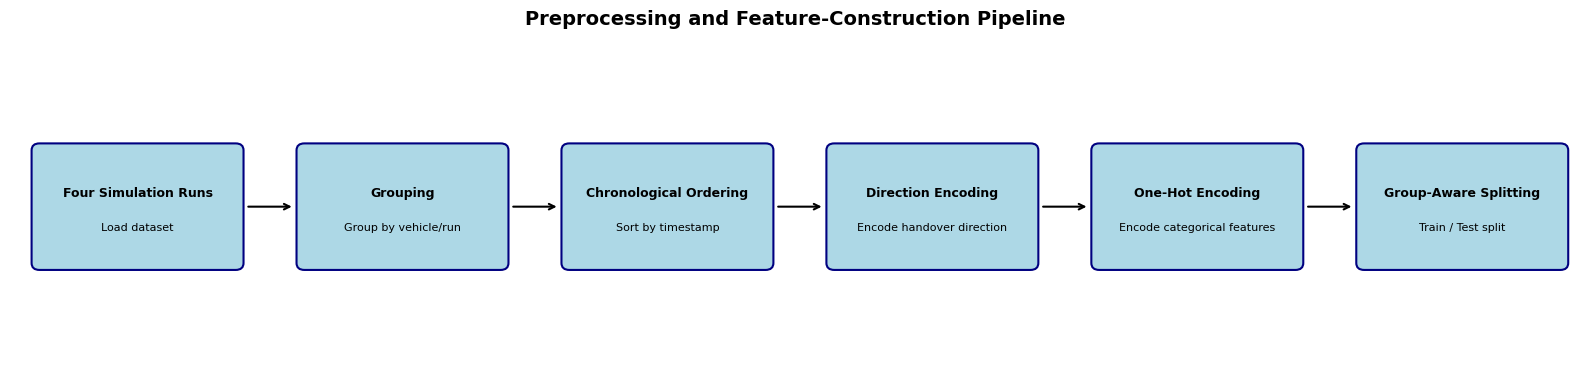

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 4))
ax.set_xlim(0, 16)
ax.set_ylim(0, 4)
ax.axis("off")

steps = [
    ("Four Simulation Runs", "Load dataset"),
    ("Grouping", "Group by vehicle/run"),
    ("Chronological Ordering", "Sort by timestamp"),
    ("Direction Encoding", "Encode handover direction"),
    ("One-Hot Encoding", "Encode categorical features"),
    ("Group-Aware Splitting", "Train / Test split")
]

x_positions = [0.3, 3.0, 5.7, 8.4, 11.1, 13.8]

for i, (title, subtitle) in enumerate(steps):
    box = FancyBboxPatch(
        (x_positions[i], 1.35), 2.0, 1.3,
        boxstyle="round,pad=0.08",
        edgecolor="navy",
        facecolor="lightblue",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(x_positions[i] + 1, 2.15, title,
            ha="center", va="center",
            fontsize=9, weight="bold", wrap=True)

    ax.text(x_positions[i] + 1, 1.75, subtitle,
            ha="center", va="center", fontsize=8)

    if i < len(steps) - 1:
        ax.annotate(
            "", xy=(x_positions[i+1] - 0.1, 2),
            xytext=(x_positions[i] + 2.1, 2),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

plt.title("Preprocessing and Feature-Construction Pipeline",
          fontsize=14, weight="bold")

plt.tight_layout()
plt.savefig("preprocessing_pipeline.png",
            dpi=300, bbox_inches="tight")
plt.show()

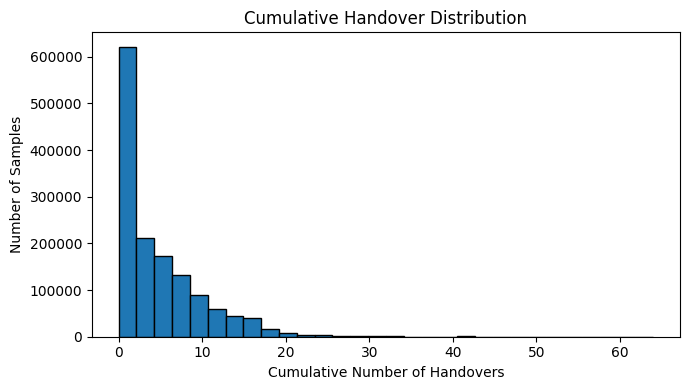

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.hist(
    df['cumulative_handovers'],
    bins=30,
    edgecolor='black'
)

plt.xlabel('Cumulative Number of Handovers')
plt.ylabel('Number of Samples')
plt.title('Cumulative Handover Distribution')

plt.tight_layout()
plt.savefig(
    'cumulative_handover_distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# **Cell 10 — Train, validation and test splitting**

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["group_id"].to_numpy()

indices = np.arange(len(df))

# First split: 80% train/validation, 20% test
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

trainval_idx, test_idx = next(
    split1.split(indices, y_handover, groups)
)

# Second split: 15% validation, 65% training overall
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1875,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        trainval_idx,
        y_handover.iloc[trainval_idx],
        groups[trainval_idx]
    )
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nVehicle counts:")

print("Train:", len(set(groups[train_idx])))
print("Validation:", len(set(groups[val_idx])))
print("Test:", len(set(groups[test_idx])))

assert set(groups[train_idx]).isdisjoint(groups[val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

Train: 920573
Validation: 204782
Test: 282916

Vehicle counts:
Train: 2551
Validation: 589
Test: 785


# **Cell 11 — Preprocessing and normalization**

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# Separate numerical and categorical columns
n_num = len(NUMERIC_FEATURES)

def prepare_features(indices, fit=False):

    raw = X.iloc[indices]

    num = raw.iloc[:, :n_num].to_numpy()
    cat = raw.iloc[:, n_num:].to_numpy()

    if fit:

        num = imputer.fit_transform(num)
        num = scaler.fit_transform(num)

    else:

        num = imputer.transform(num)
        num = scaler.transform(num)

    return np.hstack([
        num.astype(np.float32),
        cat.astype(np.float32)
    ]).astype(np.float32)


X_train = prepare_features(train_idx, fit=True)
X_val = prepare_features(val_idx)
X_test = prepare_features(test_idx)

y_train = y_handover.iloc[train_idx].to_numpy()
y_val = y_handover.iloc[val_idx].to_numpy()
y_test = y_handover.iloc[test_idx].to_numpy()

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Testing matrix:", X_test.shape)

Training matrix: (920573, 57)
Validation matrix: (204782, 57)
Testing matrix: (282916, 57)


# **Cell 12 — Handle class imbalance**

In [ ]:
from sklearn.model_selection import train_test_split

MAX_TRAIN_ROWS = 300_000

if len(y_train) > MAX_TRAIN_ROWS:

    selected, _ = train_test_split(
        np.arange(len(y_train)),
        train_size=MAX_TRAIN_ROWS,
        stratify=y_train,
        random_state=42
    )

    X_train = X_train[selected]
    y_train = y_train[selected]

print("Training size:", len(y_train))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nPositive class percentage:",
      100 * y_train.mean())

Training size: 300000

Training class distribution:
0    293899
1      6101
Name: count, dtype: int64

Positive class percentage: 2.0336666666666665


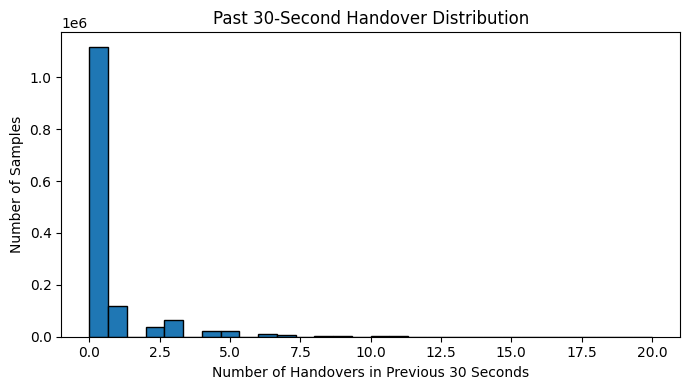

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.hist(
    df['past_count_30s'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.xlabel('Number of Handovers in Previous 30 Seconds')
plt.ylabel('Number of Samples')
plt.title('Past 30-Second Handover Distribution')

plt.tight_layout()

plt.savefig(
    'past_30s_handover_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

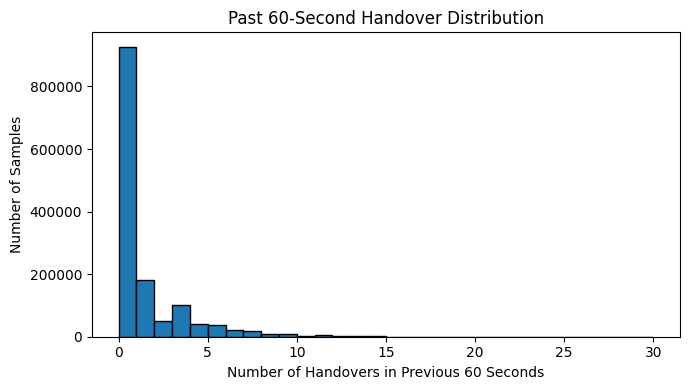

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.hist(
    df['past_count_60s'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.xlabel('Number of Handovers in Previous 60 Seconds')
plt.ylabel('Number of Samples')
plt.title('Past 60-Second Handover Distribution')

plt.tight_layout()

plt.savefig(
    'past_60s_handover_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# **Cell 13 — Train the probabilistic models**

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.linear_model import LogisticRegression

models = {

    "Gaussian Naive Bayes": GaussianNB(),

    "LDA": LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    ),

    "QDA": QuadraticDiscriminantAnalysis(
        reg_param=0.2
    ),

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="lbfgs",
        random_state=42
    )
}

binary_probabilities = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]

    binary_probabilities[name] = {
        "validation": val_prob,
        "test": test_prob
    }

    print("Completed:", name)


Training: Gaussian Naive Bayes
Completed: Gaussian Naive Bayes

Training: LDA
Completed: LDA

Training: QDA
Completed: QDA

Training: Logistic Regression
Completed: Logistic Regression


# **Cell 14 — Gaussian Mixture Model**

In [ ]:
from sklearn.mixture import GaussianMixture

rng = np.random.default_rng(42)

GMM_TRAIN_SIZE = min(50000, len(X_train))

gmm_idx = rng.choice(
    len(X_train),
    size=GMM_TRAIN_SIZE,
    replace=False
)

gmm = GaussianMixture(
    n_components=8,
    covariance_type="diag",
    reg_covar=1e-4,
    max_iter=100,
    random_state=42
)

gmm.fit(X_train[gmm_idx])

# Responsibilities for training observations
train_resp = gmm.predict_proba(X_train[gmm_idx])

# Handover probability for each component
component_handover_rate = (
    train_resp.T @ y_train[gmm_idx] + 1
) / (
    train_resp.sum(axis=0) + 2
)

# Predict on validation and test sets
val_resp = gmm.predict_proba(X_val)
test_resp = gmm.predict_proba(X_test)

gmm_val_prob = val_resp @ component_handover_rate
gmm_test_prob = test_resp @ component_handover_rate

binary_probabilities["Gaussian Mixture Model"] = {
    "validation": gmm_val_prob,
    "test": gmm_test_prob
}

print("GMM completed.")
print("Component handover probabilities:")
print(component_handover_rate)

GMM completed.
Component handover probabilities:
[0.00782677 0.00520168 0.0259522  0.03901948 0.02135055 0.00472789
 0.21972237 0.04001753]


# **Cell 15 — Bayesian Logistic Regression**

In [ ]:
from scipy.optimize import minimize
from scipy.special import expit

# Use a manageable subset for Bayesian posterior estimation
BAYES_TRAIN_SIZE = min(80000, len(X_train))

bayes_idx = rng.choice(
    len(X_train),
    size=BAYES_TRAIN_SIZE,
    replace=False
)

Xb = X_train[bayes_idx].astype(np.float64)
yb = y_train[bayes_idx].astype(np.float64)

# Add intercept
Xb = np.column_stack([
    np.ones(len(Xb)),
    Xb
])

# Gaussian prior precision
alpha = 1.0

def objective(w):

    z = Xb @ w

    likelihood_loss = np.sum(
        np.logaddexp(0, z) - yb * z
    )

    prior_loss = (
        0.5 * alpha * np.sum(w[1:] ** 2)
    )

    return likelihood_loss + prior_loss


def gradient(w):

    p = expit(Xb @ w)

    grad = Xb.T @ (p - yb)

    grad[1:] += alpha * w[1:]

    return grad


initial_weights = np.zeros(Xb.shape[1])

result = minimize(
    objective,
    initial_weights,
    jac=gradient,
    method="L-BFGS-B",
    options={"maxiter": 300}
)

map_weights = result.x

print("MAP optimization successful:", result.success)
print("Final loss:", result.fun)

MAP optimization successful: True
Final loss: 5172.044248110423


In [ ]:
p_train = expit(Xb @ map_weights)

weights = p_train * (1 - p_train)

H = Xb.T @ (
    Xb * weights[:, None]
)

H[1:, 1:] += alpha * np.eye(
    Xb.shape[1] - 1
)

H[0, 0] += 1e-6

posterior_covariance = np.linalg.pinv(H)

print("Posterior covariance calculated.")

Posterior covariance calculated.


In [ ]:
N_SAMPLES = 100

posterior_weights = rng.multivariate_normal(
    map_weights,
    posterior_covariance,
    size=N_SAMPLES
)

In [ ]:
def bayesian_predict(X, posterior_weights, batch_size=20000):

    mean_predictions = []
    std_predictions = []

    for start in range(0, len(X), batch_size):

        xb = X[start:start + batch_size]

        xb = np.column_stack([
            np.ones(len(xb)),
            xb
        ])

        predictions = expit(
            xb @ posterior_weights.T
        )

        mean_predictions.extend(
            predictions.mean(axis=1)
        )

        std_predictions.extend(
            predictions.std(axis=1)
        )

    return (
        np.array(mean_predictions),
        np.array(std_predictions)
    )


bayes_val_prob, bayes_val_uncertainty = bayesian_predict(
    X_val, posterior_weights
)

bayes_test_prob, bayes_test_uncertainty = bayesian_predict(
    X_test, posterior_weights
)

binary_probabilities["Bayesian Logistic Regression"] = {
    "validation": bayes_val_prob,
    "test": bayes_test_prob
}

print("Bayesian Logistic Regression completed!")

print("Mean predictive uncertainty:",
      bayes_test_uncertainty.mean())

Bayesian Logistic Regression completed!
Mean predictive uncertainty: 0.002951225315461446


In [ ]:
import numpy as np
from scipy.special import expit

# ------------------------------------------------
# 1. Calculate Hessian at MAP estimate
# ------------------------------------------------

p_map = expit(Xb @ map_weights)

W = p_map * (1 - p_map)

H = (Xb.T * W) @ Xb

# Gaussian prior precision (do not penalize intercept)
prior_precision = np.eye(len(map_weights)) * alpha
prior_precision[0, 0] = 0

H += prior_precision

# ------------------------------------------------
# 2. Approximate posterior covariance
# ------------------------------------------------

posterior_cov = np.linalg.inv(H + 1e-6 * np.eye(len(H)))

# ------------------------------------------------
# 3. Generate posterior weight samples
# ------------------------------------------------

NUM_POSTERIOR_SAMPLES = 100

posterior_weights = rng.multivariate_normal(
    mean=map_weights,
    cov=posterior_cov,
    size=NUM_POSTERIOR_SAMPLES
)

print("Posterior samples shape:", posterior_weights.shape)

Posterior samples shape: (100, 58)


In [ ]:
# Select validation observations
X_uncertainty = X_val[:5000].astype(np.float64)

# Add intercept
X_uncertainty = np.column_stack([
    np.ones(len(X_uncertainty)),
    X_uncertainty
])

# Generate predictions from posterior weight samples
prob_samples = expit(
    posterior_weights @ X_uncertainty.T
)

# Mean predictive probability
bayesian_probability = np.mean(
    prob_samples, axis=0
)

# Predictive uncertainty
predictive_uncertainty = np.std(
    prob_samples, axis=0
)

print("Probability shape:", bayesian_probability.shape)
print("Uncertainty shape:", predictive_uncertainty.shape)

Probability shape: (5000,)
Uncertainty shape: (5000,)


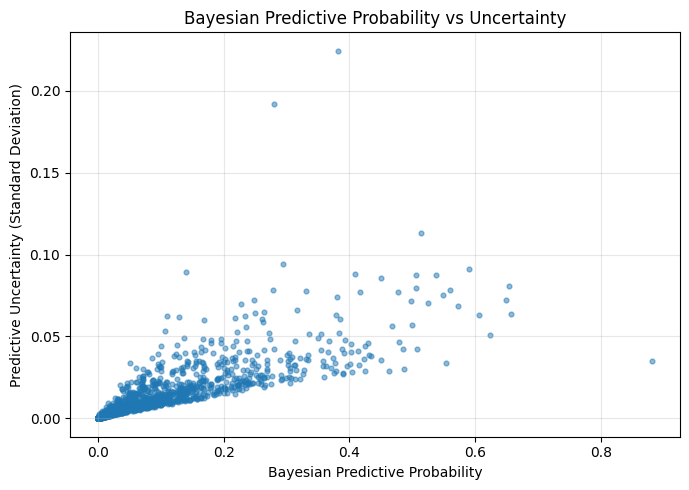

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    bayesian_probability,
    predictive_uncertainty,
    alpha=0.5,
    s=12
)

plt.xlabel("Bayesian Predictive Probability")
plt.ylabel("Predictive Uncertainty (Standard Deviation)")

plt.title("Bayesian Predictive Probability vs Uncertainty")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "bayesian_probability_uncertainty.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Cell 16 — Choose a decision threshold using validation data**

In [ ]:
from sklearn.metrics import fbeta_score

def find_best_threshold(y_true, probabilities):

    thresholds = np.linspace(
        0.01, 0.99, 99
    )

    scores = []

    for threshold in thresholds:

        pred = (
            probabilities >= threshold
        ).astype(int)

        score = fbeta_score(
            y_true,
            pred,
            beta=2,
            zero_division=0
        )

        scores.append(score)

    best_index = np.argmax(scores)

    return (
        thresholds[best_index],
        scores[best_index]
    )


best_thresholds = {}

for name, probs in binary_probabilities.items():

    threshold, score = find_best_threshold(
        y_val,
        probs["validation"]
    )

    best_thresholds[name] = threshold

    print(
        name,
        "Threshold:", threshold,
        "Validation F2:", score
    )

Gaussian Naive Bayes Threshold: 0.87 Validation F2: 0.23054046197535832
LDA Threshold: 0.05 Validation F2: 0.36772868561278865
QDA Threshold: 0.03 Validation F2: 0.4346327310332941
Logistic Regression Threshold: 0.65 Validation F2: 0.41388742262104705
Gaussian Mixture Model Threshold: 0.04 Validation F2: 0.1783078404107391
Bayesian Logistic Regression Threshold: 0.060000000000000005 Validation F2: 0.40999830345529603


# **Cell 17 — Evaluate binary handover prediction**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix
)

binary_results = []

for name, probs in binary_probabilities.items():

    prob = probs["test"]

    threshold = best_thresholds[name]

    pred = (
        prob >= threshold
    ).astype(int)

    binary_results.append({

        "Model": name,

        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test, pred
        ),

        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),

        "F1": f1_score(
            y_test, pred, zero_division=0
        ),

        "F2": fbeta_score(
            y_test, pred, beta=2,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test, prob
        ),

        "PR-AUC": average_precision_score(
            y_test, prob
        ),

        "Brier Score": brier_score_loss(
            y_test, prob
        )
    })


binary_results_df = pd.DataFrame(binary_results)

display(
    binary_results_df.sort_values(
        "PR-AUC",
        ascending=False
    )
)

,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,Brier Score
5,Bayesian Logistic Regression,0.06,0.914568,0.154127,0.704252,0.252906,0.410916,0.937036,0.219395,0.017612
1,LDA,0.05,0.904961,0.132245,0.652436,0.219914,0.365160,0.894284,0.217265,0.018153
2,QDA,0.03,0.917067,0.163913,0.741091,0.268450,0.434848,0.936724,0.215836,0.018774
3,Logistic Regression,0.65,0.891052,0.139962,0.836977,0.239820,0.419326,0.939863,0.201307,0.109703
0,Gaussian Naive Bayes,0.87,0.858902,0.071805,0.492339,0.125331,0.226747,0.807626,0.074824,0.160069
4,Gaussian Mixture Model,0.04,0.841013,0.054500,0.412463,0.096279,0.178276,0.755355,0.071996,0.019297


# **Cell 18 — Compare with a simple baseline**

In [ ]:
baseline_prediction = np.zeros(
    len(y_test),
    dtype=int
)

print("Majority-class baseline")

print("Accuracy:",
      accuracy_score(y_test, baseline_prediction))

print("Recall:",
      recall_score(y_test, baseline_prediction,
                   zero_division=0))

print("F1:",
      f1_score(y_test, baseline_prediction,
               zero_division=0))

print("Positive test cases:", y_test.sum())

Majority-class baseline
Accuracy: 0.9794674037523505
Recall: 0.0
F1: 0.0
Positive test cases: 5809


# **Cell 19 — Confusion matrix**

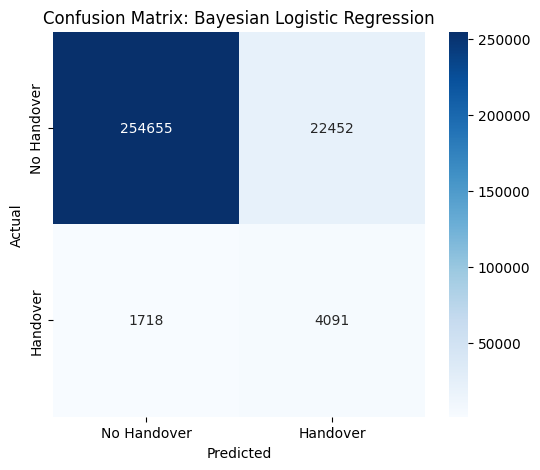

In [ ]:
best_model_name = max(
    binary_results,
    key=lambda x: x["PR-AUC"]
)["Model"]

best_prob = binary_probabilities[
    best_model_name
]["test"]

best_pred = (
    best_prob >= best_thresholds[best_model_name]
).astype(int)

cm = confusion_matrix(
    y_test,
    best_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Handover", "Handover"],
    yticklabels=["No Handover", "Handover"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best_model_name}")

plt.show()

# **Cell 20 — Compare Bayesian uncertainty**

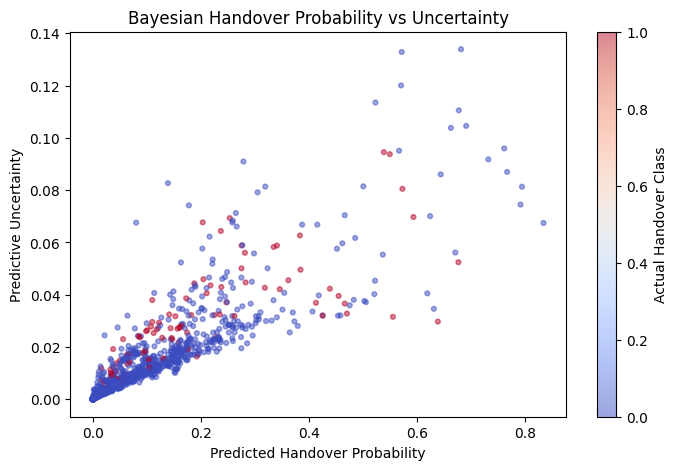

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    bayes_test_prob[:5000],
    bayes_test_uncertainty[:5000],
    c=y_test[:5000],
    cmap="coolwarm",
    alpha=0.5,
    s=12
)

plt.xlabel("Predicted Handover Probability")
plt.ylabel("Predictive Uncertainty")

plt.title("Bayesian Handover Probability vs Uncertainty")

plt.colorbar(label="Actual Handover Class")

plt.show()

# **Cell 21 — Destination-cell prediction**

In [ ]:
# Recover the original row indices corresponding to the
# training samples used by the binary models.

if len(train_idx) > MAX_TRAIN_ROWS:
    train_idx_model = train_idx[selected]
else:
    train_idx_model = train_idx.copy()

print("Training rows retained:", len(train_idx_model))

Training rows retained: 300000


In [ ]:
# Warning-window masks
train_warning = (
    df.iloc[train_idx_model]["migration"].to_numpy() > 0
)

val_warning = (
    df.iloc[val_idx]["migration"].to_numpy() > 0
)

test_warning = (
    df.iloc[test_idx]["migration"].to_numpy() > 0
)

# Feature subsets
X_train_dest = X_train[train_warning]
X_val_dest = X_val[val_warning]
X_test_dest = X_test[test_warning]

# Destination labels
y_train_dest = (
    df.iloc[train_idx_model]
    .loc[train_warning, "destination"]
    .to_numpy()
)

y_val_dest = (
    df.iloc[val_idx]
    .loc[val_warning, "destination"]
    .to_numpy()
)

y_test_dest = (
    df.iloc[test_idx]
    .loc[test_warning, "destination"]
    .to_numpy()
)

print("Destination training samples:", len(y_train_dest))
print("Destination validation samples:", len(y_val_dest))
print("Destination testing samples:", len(y_test_dest))

print("\nTraining destination distribution:")
print(pd.Series(y_train_dest).value_counts().sort_index())

print("\nTesting destination distribution:")
print(pd.Series(y_test_dest).value_counts().sort_index())

Destination training samples: 6101
Destination validation samples: 4108
Destination testing samples: 5809

Training destination distribution:
1     187
2    1233
3     612
4     330
5     546
6     652
7    1220
8     336
9     985
Name: count, dtype: int64

Testing destination distribution:
1     164
2    1242
3     426
4     286
5     474
6     605
7    1296
8     339
9     977
Name: count, dtype: int64


# **Cell 22 — Train multiclass probabilistic models**

In [ ]:
destination_models = {

    "Gaussian Naive Bayes": GaussianNB(),

    "LDA": LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    ),

    "QDA": QuadraticDiscriminantAnalysis(
        reg_param=0.2
    ),

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="lbfgs",
        random_state=42
    )
}

destination_probabilities = {}

for name, model in destination_models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_dest,
        y_train_dest
    )

    val_prob = model.predict_proba(X_val_dest)
    test_prob = model.predict_proba(X_test_dest)

    destination_probabilities[name] = {
        "classes": model.classes_,
        "validation": val_prob,
        "test": test_prob
    }

    print("Completed:", name)


Training: Gaussian Naive Bayes
Completed: Gaussian Naive Bayes

Training: LDA
Completed: LDA

Training: QDA
Completed: QDA

Training: Logistic Regression
Completed: Logistic Regression


# **Cell 23 — GMM for destination prediction**

In [ ]:
# ============================================================
# DESTINATION GMM: FEATURE PREPROCESSING
# ============================================================

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

# Remove zero-variance features
variance_filter = VarianceThreshold(threshold=0.0)

X_train_filtered = variance_filter.fit_transform(X_train_dest)
X_val_filtered = variance_filter.transform(X_val_dest)
X_test_filtered = variance_filter.transform(X_test_dest)

print("Original features:", X_train_dest.shape[1])
print("Remaining features:", X_train_filtered.shape[1])

# Standardize features
gmm_scaler = StandardScaler()

X_train_gmm = gmm_scaler.fit_transform(X_train_filtered)
X_val_gmm = gmm_scaler.transform(X_val_filtered)
X_test_gmm = gmm_scaler.transform(X_test_filtered)

print("GMM preprocessing completed.")

Original features: 57
Remaining features: 57
GMM preprocessing completed.


,Components,Validation Log Loss,BIC,AIC,Converged
8,15,1.020686,-88508.472673,-100087.215215,True
7,12,1.081353,-63432.950631,-72694.601423,True
6,10,1.129506,-19706.547801,-27423.470760,True
5,8,1.236289,20125.549751,13953.354626,True
3,5,1.338688,156851.787176,152996.683801,True
4,6,1.372848,66353.092926,61725.625634,True
2,4,1.525535,223942.684886,220859.945428,True
1,3,1.575716,323886.127150,321575.751608,True
0,2,1.759396,545863.103917,544325.092292,True


Selected GMM components: 15
Converged: True
Iterations: 14
BIC: -88508.47267274107
AIC: -100087.21521500687

VALIDATION RESULTS
Accuracy: 0.5555014605647517
Macro F1: 0.4883854673077866
Weighted F1: 0.513332520007231
Log Loss: 1.020685668246375

TEST RESULTS
Accuracy: 0.5627474608366329
Macro F1: 0.4918782010783161
Weighted F1: 0.5171016507484896
Log Loss: 1.0045403577963907
Top-3 Test Accuracy: 0.9726286796350491


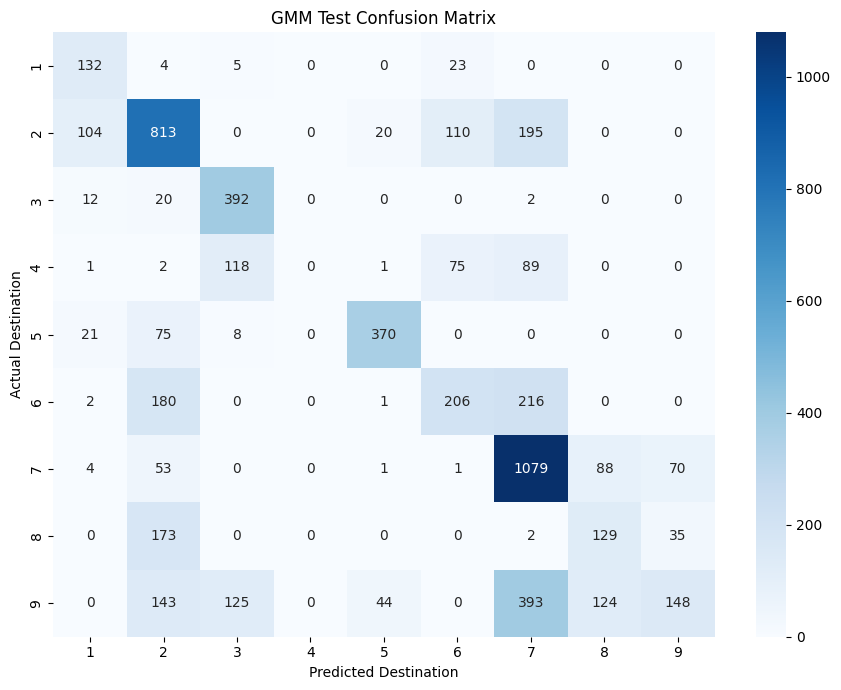

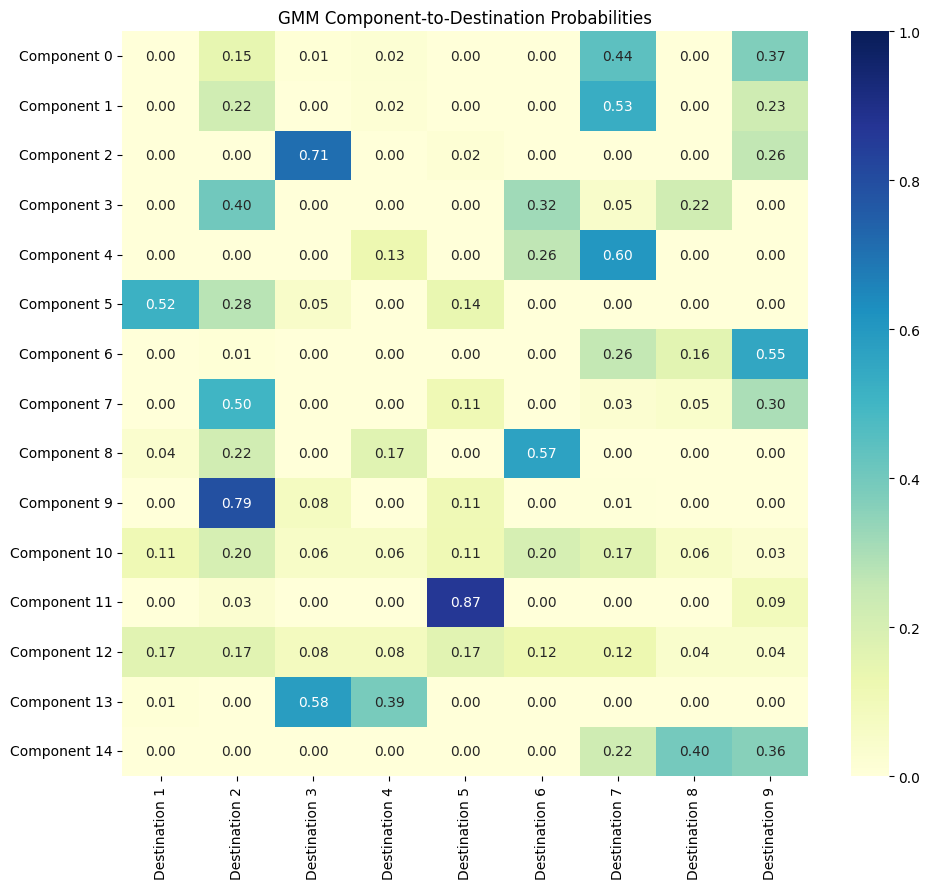


Destination GMM completed.


In [ ]:
# ============================================================
# DESTINATION GMM: MODEL SELECTION AND FINAL EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss,
    confusion_matrix
)

# ------------------------------------------------------------
# STEP 1: SELECT COMPONENTS USING VALIDATION LOG LOSS
# ------------------------------------------------------------

classes = np.sort(np.unique(y_train_dest))

component_values = [2, 3, 4, 5, 6, 8, 10, 12, 15]

gmm_comparison = []

for k in component_values:

    candidate = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        reg_covar=0.01,
        max_iter=300,
        n_init=5,
        random_state=42
    )

    candidate.fit(X_train_gmm)

    train_resp = candidate.predict_proba(X_train_gmm)
    val_resp = candidate.predict_proba(X_val_gmm)

    Y_onehot = (
        y_train_dest[:, None] == classes[None, :]
    ).astype(float)

    alpha = 1.0

    component_probs = (
        train_resp.T @ Y_onehot + alpha
    ) / (
        train_resp.sum(axis=0)[:, None]
        + alpha * len(classes)
    )

    val_probs = val_resp @ component_probs

    val_loss = log_loss(
        y_val_dest,
        val_probs,
        labels=classes
    )

    gmm_comparison.append({
        "Components": k,
        "Validation Log Loss": val_loss,
        "BIC": candidate.bic(X_train_gmm),
        "AIC": candidate.aic(X_train_gmm),
        "Converged": candidate.converged_
    })

gmm_comparison = pd.DataFrame(gmm_comparison)

display(
    gmm_comparison.sort_values(
        "Validation Log Loss"
    )
)

# Select the number of components with lowest validation log loss
best_k = int(
    gmm_comparison.loc[
        gmm_comparison["Validation Log Loss"].idxmin(),
        "Components"
    ]
)

print("Selected GMM components:", best_k)

# ------------------------------------------------------------
# STEP 2: TRAIN FINAL GMM
# ------------------------------------------------------------

gmm_dest = GaussianMixture(
    n_components=best_k,
    covariance_type="diag",
    reg_covar=0.01,
    max_iter=300,
    n_init=5,
    random_state=42
)

gmm_dest.fit(X_train_gmm)

print("Converged:", gmm_dest.converged_)
print("Iterations:", gmm_dest.n_iter_)
print("BIC:", gmm_dest.bic(X_train_gmm))
print("AIC:", gmm_dest.aic(X_train_gmm))

# ------------------------------------------------------------
# STEP 3: COMPONENT RESPONSIBILITIES
# ------------------------------------------------------------

resp_train_dest = gmm_dest.predict_proba(X_train_gmm)
resp_val_dest = gmm_dest.predict_proba(X_val_gmm)
resp_test_dest = gmm_dest.predict_proba(X_test_gmm)

# ------------------------------------------------------------
# STEP 4: COMPONENT-TO-DESTINATION PROBABILITIES
# ------------------------------------------------------------

Y_onehot = (
    y_train_dest[:, None] == classes[None, :]
).astype(float)

alpha = 1.0

component_destination_probs = (
    resp_train_dest.T @ Y_onehot + alpha
) / (
    resp_train_dest.sum(axis=0)[:, None]
    + alpha * len(classes)
)

gmm_dest_val = (
    resp_val_dest @ component_destination_probs
)

gmm_dest_test = (
    resp_test_dest @ component_destination_probs
)

destination_probabilities["Gaussian Mixture Model"] = {
    "classes": classes,
    "validation": gmm_dest_val,
    "test": gmm_dest_test
}

# ------------------------------------------------------------
# STEP 5: VALIDATION PERFORMANCE
# ------------------------------------------------------------

val_predictions = classes[
    np.argmax(gmm_dest_val, axis=1)
]

print("\nVALIDATION RESULTS")
print("Accuracy:",
      accuracy_score(y_val_dest, val_predictions))

print("Macro F1:",
      f1_score(
          y_val_dest,
          val_predictions,
          average="macro",
          zero_division=0
      ))

print("Weighted F1:",
      f1_score(
          y_val_dest,
          val_predictions,
          average="weighted",
          zero_division=0
      ))

print("Log Loss:",
      log_loss(
          y_val_dest,
          gmm_dest_val,
          labels=classes
      ))

# ------------------------------------------------------------
# STEP 6: TEST PERFORMANCE
# ------------------------------------------------------------

test_predictions = classes[
    np.argmax(gmm_dest_test, axis=1)
]

print("\nTEST RESULTS")
print("Accuracy:",
      accuracy_score(y_test_dest, test_predictions))

print("Macro F1:",
      f1_score(
          y_test_dest,
          test_predictions,
          average="macro",
          zero_division=0
      ))

print("Weighted F1:",
      f1_score(
          y_test_dest,
          test_predictions,
          average="weighted",
          zero_division=0
      ))

print("Log Loss:",
      log_loss(
          y_test_dest,
          gmm_dest_test,
          labels=classes
      ))

# ------------------------------------------------------------
# STEP 7: TOP-3 ACCURACY
# ------------------------------------------------------------

top_k = min(3, len(classes))

top_indices = np.argsort(
    gmm_dest_test,
    axis=1
)[:, -top_k:]

top_classes = classes[top_indices]

top3_accuracy = np.mean([
    y_test_dest[i] in top_classes[i]
    for i in range(len(y_test_dest))
])

print("Top-3 Test Accuracy:", top3_accuracy)

# ------------------------------------------------------------
# STEP 8: CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_dest,
    test_predictions,
    labels=classes
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Destination")
plt.ylabel("Actual Destination")
plt.title("GMM Test Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 9: COMPONENT-TO-DESTINATION HEATMAP
# ------------------------------------------------------------

component_df = pd.DataFrame(
    component_destination_probs,
    index=[f"Component {i}" for i in range(best_k)],
    columns=[f"Destination {c}" for c in classes]
)

plt.figure(figsize=(10, max(4, best_k * 0.6)))

sns.heatmap(
    component_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title("GMM Component-to-Destination Probabilities")
plt.tight_layout()
plt.show()

print("\nDestination GMM completed.")

In [ ]:
import numpy as np

print("Shape:", X_train_dest.shape)
print("NaN:", np.isnan(X_train_dest).sum())
print("Inf:", np.isinf(X_train_dest).sum())

print("Minimum:", np.min(X_train_dest))
print("Maximum:", np.max(X_train_dest))

print("Feature variances:")
print(np.var(X_train_dest, axis=0))

print("Unique samples:", np.unique(X_train_dest, axis=0).shape[0])
print("Training samples:", len(X_train_dest))

Shape: (6101, 57)
NaN: 0
Inf: 0
Minimum: -3.199301
Maximum: 30.788607
Feature variances:
[9.0811861e-01 6.4375979e-01 1.0360548e+00 8.3881325e-01 7.6498955e-01
 9.4848442e-01 1.0895104e+00 8.1083769e-01 2.0503692e-01 5.0849265e-01
 4.5535132e-01 5.7746166e-01 1.4040257e+00 8.6076880e-01 6.7771757e-01
 4.6310399e-02 1.6473994e-01 8.2825311e-02 5.2474286e-02 8.3897628e-02
 8.9720361e-02 1.6328725e-01 5.8688980e-02 1.1777521e-01 2.4524659e-03
 1.1461052e-03 5.2186348e-02 1.6662984e-01 8.4031254e-02 5.8833655e-02
 8.3762959e-02 8.4831096e-02 1.5780528e-01 5.9262946e-02 1.1235979e-01
 5.2171699e-03 8.1887899e-04 5.1455129e-02 1.6520542e-01 8.2286239e-02
 5.8689121e-02 8.4697776e-02 8.6690269e-02 1.5630226e-01 6.0410604e-02
 1.1295845e-01 6.6753202e-03 9.8246802e-04 5.4219618e-02 1.6824627e-01
 7.9865165e-02 5.8688883e-02 8.1884101e-02 8.6821668e-02 1.5397811e-01
 6.1834995e-02 1.1174125e-01]
Unique samples: 6101
Training samples: 6101


In [ ]:
classes = np.sort(np.unique(y_train_dest))

# One-hot encode destination labels
Y_dest_onehot = (
    y_train_dest[:, None] == classes[None, :]
).astype(float)

# Estimate destination probabilities per component
alpha = 1.0

component_destination_probs = (
    resp_train_dest.T @ Y_dest_onehot + alpha
) / (
    resp_train_dest.sum(axis=0)[:, None]
    + alpha * len(classes)
)

# Destination probabilities
gmm_dest_val = (
    resp_val_dest @ component_destination_probs
)

gmm_dest_test = (
    resp_test_dest @ component_destination_probs
)

destination_probabilities["Gaussian Mixture Model"] = {
    "classes": classes,
    "validation": gmm_dest_val,
    "test": gmm_dest_test
}

print("GMM destination model completed.")

GMM destination model completed.


# **Cell 24 — Evaluate destination-cell prediction**

In [ ]:
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

destination_results = []

for name, result in destination_probabilities.items():

    prob = result["test"]
    model_classes = result["classes"]

    prediction = model_classes[
        np.argmax(prob, axis=1)
    ]

    destination_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test_dest,
            prediction
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test_dest,
            prediction
        ),

        "Macro Precision": precision_score(
            y_test_dest,
            prediction,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_test_dest,
            prediction,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_test_dest,
            prediction,
            average="macro",
            zero_division=0
        ),

        "Log Loss": log_loss(
            y_test_dest,
            prob,
            labels=model_classes
        )
    })


destination_results_df = pd.DataFrame(
    destination_results
)

display(
    destination_results_df.sort_values(
        "Macro F1",
        ascending=False
    )
)

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Log Loss
3,Logistic Regression,0.896540,0.919638,0.888650,0.919638,0.902402,0.272072
2,QDA,0.854364,0.900272,0.852864,0.900272,0.866774,0.428941
1,LDA,0.841109,0.846939,0.834802,0.846939,0.839451,0.521810
0,Gaussian Naive Bayes,0.526941,0.676262,0.582418,0.676262,0.545297,13.421859
4,Gaussian Mixture Model,0.562747,0.540591,0.499034,0.540591,0.491878,1.004540


# **Cell 25 — Visualize destination prediction**

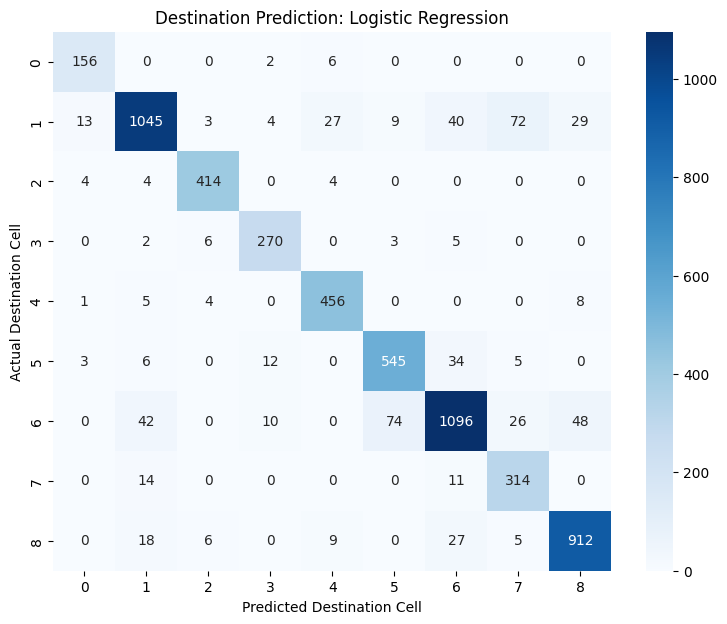

In [ ]:
best_destination_model = destination_results_df.sort_values(
    "Macro F1",
    ascending=False
).iloc[0]["Model"]

best_destination = destination_probabilities[
    best_destination_model
]

predicted_destination = best_destination["classes"][
    np.argmax(best_destination["test"], axis=1)
]

from sklearn.metrics import confusion_matrix

cm_dest = confusion_matrix(
    y_test_dest,
    predicted_destination,
    labels=np.sort(np.unique(y_test_dest))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_dest,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Destination Cell")
plt.ylabel("Actual Destination Cell")

plt.title(
    f"Destination Prediction: {best_destination_model}"
)

plt.show()

# **Cell 26 — Build a sample prediction**

In [ ]:
sample_index = 10

print("Actual handover warning:",
      y_test[sample_index])

print("Bayesian handover probability:",
      bayes_test_prob[sample_index])

print("Bayesian uncertainty:",
      bayes_test_uncertainty[sample_index])

print("Predicted handover decision:",
      "HANDOVER" if (
          bayes_test_prob[sample_index] >=
          best_thresholds["Bayesian Logistic Regression"]
      ) else "NO HANDOVER")

Actual handover warning: 0
Bayesian handover probability: 0.03554893694434514
Bayesian uncertainty: 0.004476099994141382
Predicted handover decision: NO HANDOVER


In [ ]:
destination_sample = 10

probabilities_sample = best_destination["test"][
    destination_sample
]

classes_sample = best_destination["classes"]

for cell, probability in zip(
    classes_sample,
    probabilities_sample
):

    print(
        f"Cell {cell}: {probability:.4f}"
    )

predicted_cell = classes_sample[
    np.argmax(probabilities_sample)
]

print("\nRecommended destination cell:", predicted_cell)

Cell 1: 0.0000
Cell 2: 0.0000
Cell 3: 0.0000
Cell 4: 0.0741
Cell 5: 0.0000
Cell 6: 0.3155
Cell 7: 0.6104
Cell 8: 0.0000
Cell 9: 0.0000

Recommended destination cell: 7


# **Cell 28 — Temporal train/validation/test split**

In [ ]:
# ============================================================
# CELL 28: TEMPORAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# Only retain rows with a complete 60-second future window
valid_indices = np.where(
    df["future_count_60s"].notna().to_numpy()
)[0]

temp_groups = df.loc[
    valid_indices, "group_id"
].to_numpy()

# First split: 80% train-validation, 20% test
split1_temp = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

trainval_rel, test_rel = next(
    split1_temp.split(
        valid_indices,
        groups=temp_groups
    )
)

temp_trainval_idx = valid_indices[trainval_rel]
temp_test_idx = valid_indices[test_rel]

# Second split: 65% train, 15% validation overall
split2_temp = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1875,
    random_state=42
)

train_rel, val_rel = next(
    split2_temp.split(
        temp_trainval_idx,
        groups=df.loc[
            temp_trainval_idx, "group_id"
        ].to_numpy()
    )
)

temp_train_idx = temp_trainval_idx[train_rel]
temp_val_idx = temp_trainval_idx[val_rel]

print("Temporal training rows:", len(temp_train_idx))
print("Temporal validation rows:", len(temp_val_idx))
print("Temporal testing rows:", len(temp_test_idx))

# Verify that vehicles do not overlap
train_groups = set(df.loc[temp_train_idx, "group_id"])
val_groups = set(df.loc[temp_val_idx, "group_id"])
test_groups = set(df.loc[temp_test_idx, "group_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Vehicle-wise temporal split verified.")

Temporal training rows: 763571
Temporal validation rows: 175661
Temporal testing rows: 237784
Vehicle-wise temporal split verified.


# **Cell 29 — Temporal preprocessing**

In [ ]:
# ============================================================
# CELL 29: TEMPORAL FEATURE PREPROCESSING
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Historical features available at prediction time
PAST_FEATURES = [
    "past_count_30s",
    "past_count_60s",
    "cumulative_handovers"
]

# All numeric inputs, including historical handover information
TEMP_NUMERIC_FEATURES = (
    NUMERIC_FEATURES + PAST_FEATURES
)

# Existing categorical one-hot encoded features
TEMP_CATEGORICAL_FEATURES = [
    col for col in X.columns
    if col not in NUMERIC_FEATURES
]

temp_imputer = SimpleImputer(strategy="median")
temp_scaler = StandardScaler()

def prepare_temporal_features(indices, fit=False):

    # Numeric features from original feature matrix
    num_original = X.loc[
        indices, NUMERIC_FEATURES
    ]

    # Historical handover features
    num_past = df.loc[
        indices, PAST_FEATURES
    ]

    num = pd.concat(
        [num_original, num_past],
        axis=1
    ).to_numpy()

    # Categorical features
    cat = X.loc[
        indices, TEMP_CATEGORICAL_FEATURES
    ].to_numpy()

    if fit:
        num = temp_imputer.fit_transform(num)
        num = temp_scaler.fit_transform(num)
    else:
        num = temp_imputer.transform(num)
        num = temp_scaler.transform(num)

    return np.hstack([
        num.astype(np.float32),
        cat.astype(np.float32)
    ]).astype(np.float32)


X_temp_train = prepare_temporal_features(
    temp_train_idx,
    fit=True
)

X_temp_val = prepare_temporal_features(
    temp_val_idx
)

X_temp_test = prepare_temporal_features(
    temp_test_idx
)

print("Temporal train:", X_temp_train.shape)
print("Temporal validation:", X_temp_val.shape)
print("Temporal test:", X_temp_test.shape)

# Future target arrays
y_temp_train = {
    h: df.loc[
        temp_train_idx,
        f"future_count_{h}s"
    ].to_numpy(dtype=float)
    for h in HORIZONS
}

y_temp_val = {
    h: df.loc[
        temp_val_idx,
        f"future_count_{h}s"
    ].to_numpy(dtype=float)
    for h in HORIZONS
}

y_temp_test = {
    h: df.loc[
        temp_test_idx,
        f"future_count_{h}s"
    ].to_numpy(dtype=float)
    for h in HORIZONS
}

print("Historical handover features included.")

Temporal train: (763571, 60)
Temporal validation: (175661, 60)
Temporal test: (237784, 60)
Historical handover features included.


# **Cell 30 — Train future handover count models**

In [ ]:
# ============================================================
# CELL 30: FUTURE HANDOVER COUNT PREDICTION
# ============================================================

from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

temporal_models = {}
temporal_predictions = {}
temporal_results = []

# Use a manageable random training subset
MAX_TEMP_TRAIN = 300_000

rng_temp = np.random.default_rng(42)

if len(X_temp_train) > MAX_TEMP_TRAIN:

    temp_selected = rng_temp.choice(
        len(X_temp_train),
        size=MAX_TEMP_TRAIN,
        replace=False
    )

else:
    temp_selected = np.arange(len(X_temp_train))

X_temp_train_model = X_temp_train[temp_selected]

print("Rows used for temporal training:",
      len(X_temp_train_model))

for horizon in HORIZONS:

    print("\n" + "=" * 55)
    print(f"PREDICTING HANDOVERS IN NEXT {horizon} SECONDS")
    print("=" * 55)

    y_train_h = y_temp_train[horizon][temp_selected]
    y_val_h = y_temp_val[horizon]
    y_test_h = y_temp_test[horizon]

    models_temp = {

        "Poisson Regression": PoissonRegressor(
            alpha=1.0,
            max_iter=300,
            tol=1e-5
        ),

        "Histogram Gradient Boosting": HistGradientBoostingRegressor(
            loss="poisson",
            learning_rate=0.08,
            max_iter=150,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        )
    }

    for name, model in models_temp.items():

        print("\nTraining:", name)

        model.fit(
            X_temp_train_model,
            y_train_h
        )

        # Validation predictions
        val_pred = model.predict(X_temp_val)

        # Test predictions
        test_pred = model.predict(X_temp_test)

        # Clip to positive values for Poisson deviance
        test_pred = np.maximum(
            test_pred,
            1e-8
        )

        val_pred = np.maximum(
            val_pred,
            1e-8
        )

        temporal_models[
            f"{name}_{horizon}s"
        ] = model

        temporal_predictions[
            f"{name}_{horizon}s"
        ] = {
            "validation": val_pred,
            "test": test_pred
        }

        # Evaluation
        mae = mean_absolute_error(
            y_test_h,
            test_pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test_h,
                test_pred
            )
        )

        r2 = r2_score(
            y_test_h,
            test_pred
        )

        poisson_dev = mean_poisson_deviance(
            y_test_h,
            test_pred
        )

        val_mae = mean_absolute_error(
            y_val_h,
            val_pred
        )

        temporal_results.append({

            "Horizon": f"{horizon} seconds",
            "Model": name,
            "Validation MAE": val_mae,
            "Test MAE": mae,
            "Test RMSE": rmse,
            "Test R2": r2,
            "Test Poisson Deviance": poisson_dev
        })

        print("Validation MAE:", round(val_mae, 4))
        print("Test MAE:", round(mae, 4))
        print("Test RMSE:", round(rmse, 4))
        print("Test R2:", round(r2, 4))
        print("Test Poisson Deviance:", round(poisson_dev, 4))


temporal_results_df = pd.DataFrame(
    temporal_results
)

print("\nFINAL TEMPORAL MODEL COMPARISON")

display(
    temporal_results_df.sort_values(
        ["Horizon", "Test MAE"]
    )
)

Rows used for temporal training: 300000

PREDICTING HANDOVERS IN NEXT 30 SECONDS

Training: Poisson Regression
Validation MAE: 0.7532
Test MAE: 0.7493
Test RMSE: 1.3152
Test R2: 0.1749
Test Poisson Deviance: 1.4792

Training: Histogram Gradient Boosting
Validation MAE: 0.4198
Test MAE: 0.4261
Test RMSE: 0.9659
Test R2: 0.5549
Test Poisson Deviance: 0.6402

PREDICTING HANDOVERS IN NEXT 60 SECONDS

Training: Poisson Regression
Validation MAE: 1.2509
Test MAE: 1.2433
Test RMSE: 1.9267
Test R2: 0.1935
Test Poisson Deviance: 2.1476

Training: Histogram Gradient Boosting
Validation MAE: 0.7947
Test MAE: 0.8012
Test RMSE: 1.4757
Test R2: 0.5269
Test Poisson Deviance: 1.1086

FINAL TEMPORAL MODEL COMPARISON


,Horizon,Model,Validation MAE,Test MAE,Test RMSE,Test R2,Test Poisson Deviance
1,30 seconds,Histogram Gradient Boosting,0.419789,0.426109,0.965887,0.554943,0.640183
0,30 seconds,Poisson Regression,0.753218,0.749257,1.315152,0.174884,1.479224
3,60 seconds,Histogram Gradient Boosting,0.794729,0.801179,1.475670,0.526912,1.108613
2,60 seconds,Poisson Regression,1.250874,1.243348,1.926692,0.193529,2.147620


# **Cell 31 — Past handover analysis**

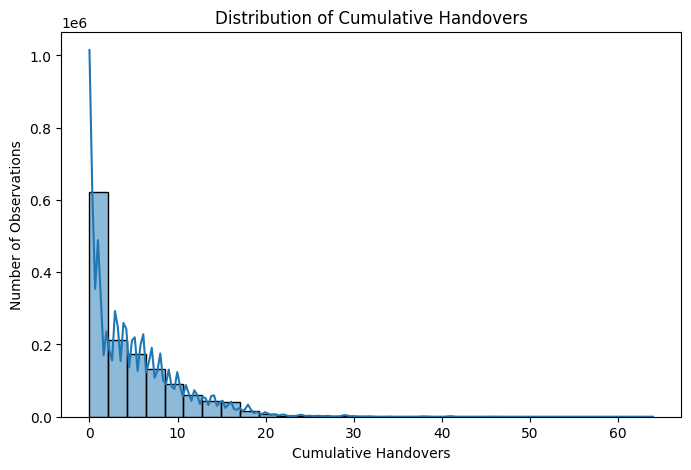

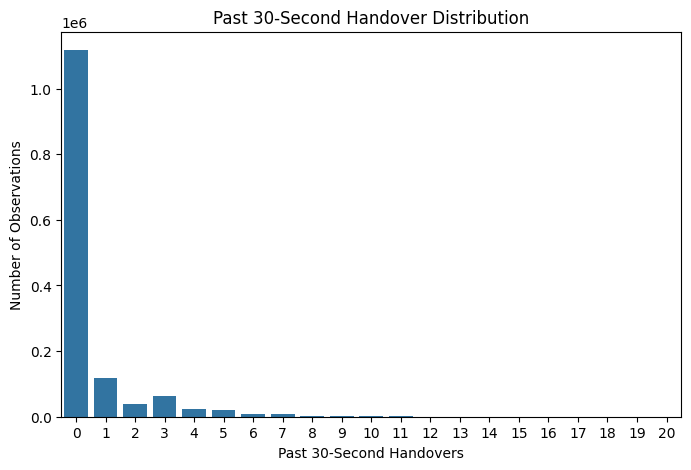

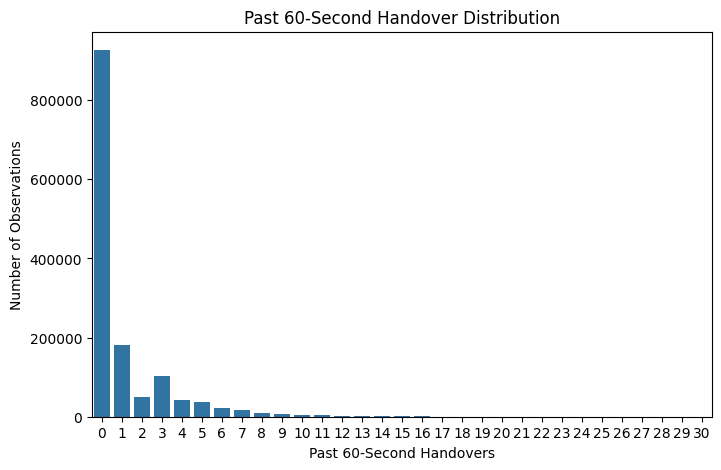

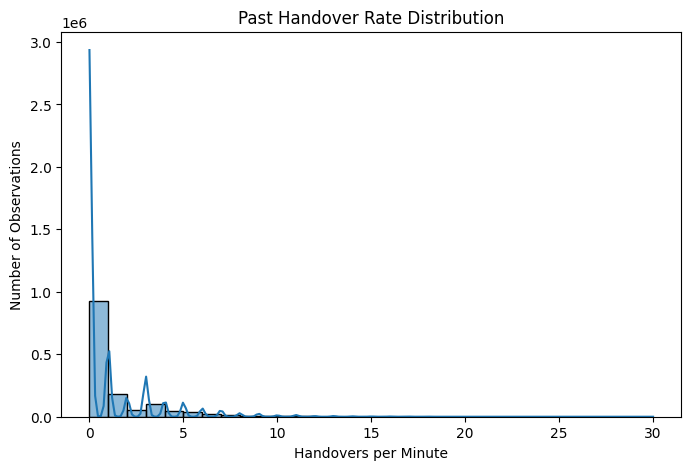

In [ ]:
# ============================================================
# CELL 31: PAST HANDOVER ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of cumulative handovers
plt.figure(figsize=(8, 5))

sns.histplot(
    df["cumulative_handovers"],
    bins=30,
    kde=True
)

plt.xlabel("Cumulative Handovers")
plt.ylabel("Number of Observations")
plt.title("Distribution of Cumulative Handovers")
plt.show()


# Past 30-second handover count
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="past_count_30s"
)

plt.xlabel("Past 30-Second Handovers")
plt.ylabel("Number of Observations")
plt.title("Past 30-Second Handover Distribution")
plt.show()


# Past 60-second handover count
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="past_count_60s"
)

plt.xlabel("Past 60-Second Handovers")
plt.ylabel("Number of Observations")
plt.title("Past 60-Second Handover Distribution")
plt.show()


# Past handover rate
plt.figure(figsize=(8, 5))

sns.histplot(
    df["past_handover_rate"],
    bins=30,
    kde=True
)

plt.xlabel("Handovers per Minute")
plt.ylabel("Number of Observations")
plt.title("Past Handover Rate Distribution")
plt.show()

# **Cell 32 — Actual versus predicted plots**

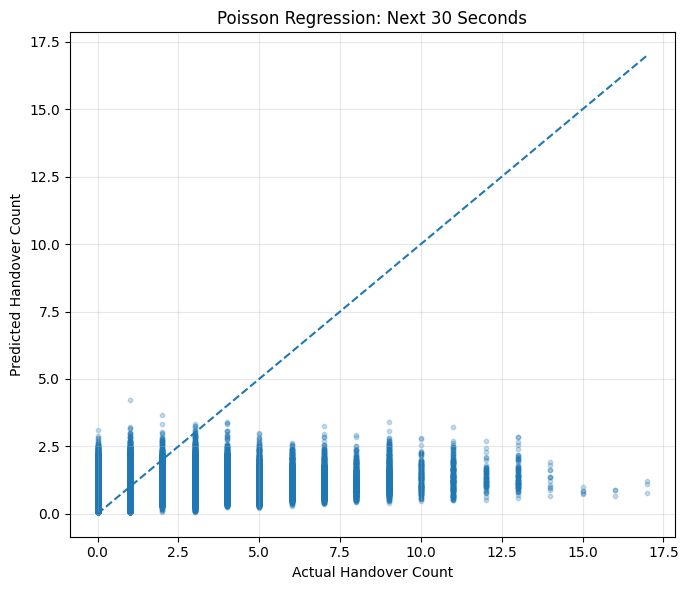

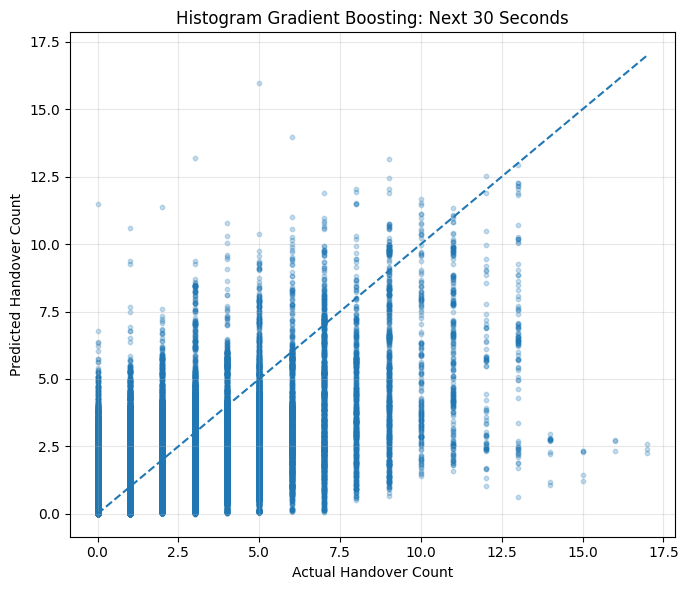

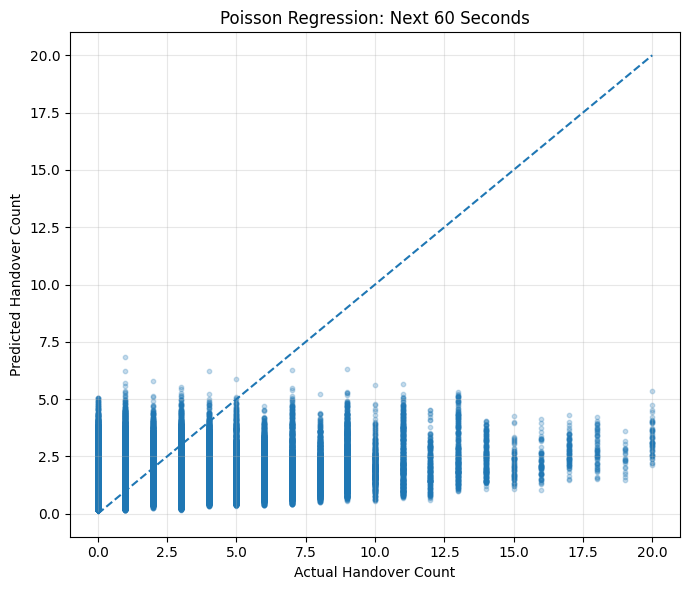

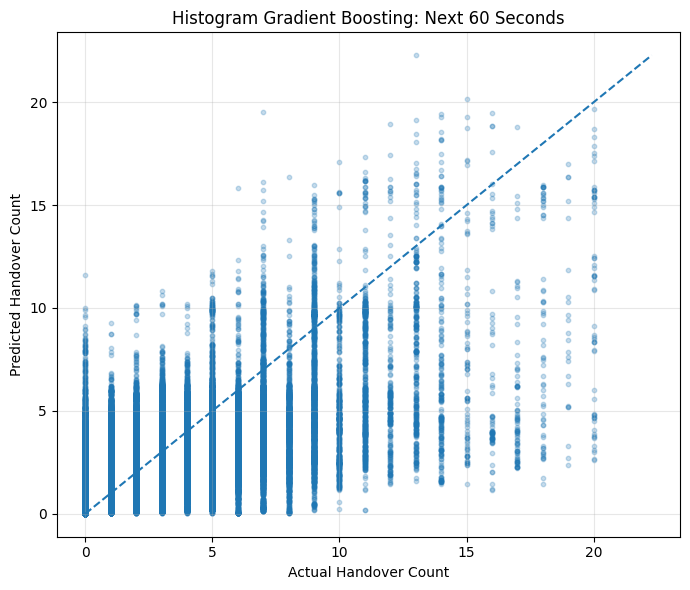

In [ ]:
# ============================================================
# CELL 32: ACTUAL VS PREDICTED HANDOVER COUNTS
# ============================================================

for horizon in HORIZONS:

    y_actual = y_temp_test[horizon]

    for model_name in [
        "Poisson Regression",
        "Histogram Gradient Boosting"
    ]:

        key = f"{model_name}_{horizon}s"

        y_pred = temporal_predictions[key]["test"]

        plt.figure(figsize=(7, 6))

        plt.scatter(
            y_actual,
            y_pred,
            alpha=0.25,
            s=10
        )

        max_value = max(
            np.max(y_actual),
            np.max(y_pred)
        )

        plt.plot(
            [0, max_value],
            [0, max_value],
            linestyle="--"
        )

        plt.xlabel("Actual Handover Count")
        plt.ylabel("Predicted Handover Count")

        plt.title(
            f"{model_name}: Next {horizon} Seconds"
        )

        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# **Cell 33 — Predict future handover rate**


Model: Poisson Regression
Horizon: 30 seconds
Mean predicted handovers per minute: 1.1267
Maximum predicted handovers per minute: 8.4736

Model: Histogram Gradient Boosting
Horizon: 30 seconds
Mean predicted handovers per minute: 1.1256
Maximum predicted handovers per minute: 31.9643

Model: Poisson Regression
Horizon: 60 seconds
Mean predicted handovers per minute: 1.1352
Maximum predicted handovers per minute: 6.8183

Model: Histogram Gradient Boosting
Horizon: 60 seconds
Mean predicted handovers per minute: 1.1332
Maximum predicted handovers per minute: 22.278


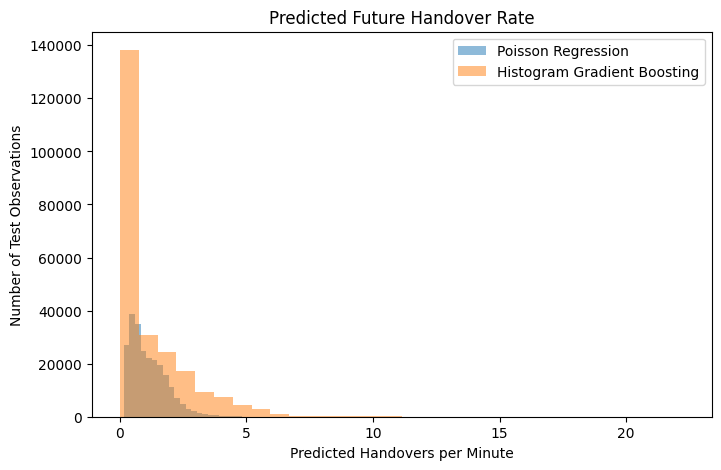

In [ ]:
# ============================================================
# CELL 33: FUTURE HANDOVER RATE PREDICTION
# ============================================================

future_rate_predictions = {}

for horizon in HORIZONS:

    for model_name in [
        "Poisson Regression",
        "Histogram Gradient Boosting"
    ]:

        key = f"{model_name}_{horizon}s"

        predicted_counts = (
            temporal_predictions[key]["test"]
        )

        # Convert predicted count into events per minute
        predicted_rate = (
            predicted_counts / horizon
        ) * 60.0

        future_rate_predictions[key] = predicted_rate

        print("\nModel:", model_name)
        print("Horizon:", horizon, "seconds")

        print(
            "Mean predicted handovers per minute:",
            round(np.mean(predicted_rate), 4)
        )

        print(
            "Maximum predicted handovers per minute:",
            round(np.max(predicted_rate), 4)
        )

# Example comparison for 60-second prediction
plt.figure(figsize=(8, 5))

for model_name in [
    "Poisson Regression",
    "Histogram Gradient Boosting"
]:

    key = f"{model_name}_60s"

    plt.hist(
        future_rate_predictions[key],
        bins=30,
        alpha=0.5,
        label=model_name
    )

plt.xlabel("Predicted Handovers per Minute")
plt.ylabel("Number of Test Observations")
plt.title("Predicted Future Handover Rate")
plt.legend()
plt.show()

# **Cell 27 — Save results**

In [ ]:
# ============================================================
# CREATE DESTINATION RESULTS DATAFRAME
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

destination_results = []

for name, result in destination_probabilities.items():

    prob = result["test"]
    model_classes = result["classes"]

    prediction = model_classes[
        np.argmax(prob, axis=1)
    ]

    destination_results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test_dest, prediction
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test_dest, prediction
        ),

        "Macro Precision": precision_score(
            y_test_dest, prediction,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_test_dest, prediction,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_test_dest, prediction,
            average="macro",
            zero_division=0
        ),

        "Log Loss": log_loss(
            y_test_dest,
            prob,
            labels=model_classes
        )
    })

destination_results_df = pd.DataFrame(destination_results)

display(
    destination_results_df.sort_values(
        "Macro F1",
        ascending=False
    )
)

print("Destination results dataframe created.")

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Log Loss
3,Logistic Regression,0.896540,0.919638,0.888650,0.919638,0.902402,0.272072
2,QDA,0.854364,0.900272,0.852864,0.900272,0.866774,0.428941
1,LDA,0.841109,0.846939,0.834802,0.846939,0.839451,0.521810
0,Gaussian Naive Bayes,0.526941,0.676262,0.582418,0.676262,0.545297,13.421859
4,Gaussian Mixture Model,0.562747,0.540591,0.499034,0.540591,0.491878,1.004540


Destination results dataframe created.


In [ ]:
# ============================================================
# CELL 27: SAVE ALL PROJECT RESULTS
# ============================================================

import joblib
import os

OUTPUT_DIR = "/content/5G_PRML_Results"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# SAVE RESULT TABLES
# ------------------------------------------------------------

binary_results_df.to_csv(
    f"{OUTPUT_DIR}/binary_handover_results.csv",
    index=False
)

destination_results_df.to_csv(
    f"{OUTPUT_DIR}/destination_results.csv",
    index=False
)

temporal_results_df.to_csv(
    f"{OUTPUT_DIR}/future_handover_results.csv",
    index=False
)

# ------------------------------------------------------------
# SAVE BINARY CLASSIFICATION MODELS
# ------------------------------------------------------------

joblib.dump(
    models,
    f"{OUTPUT_DIR}/binary_models.pkl"
)

joblib.dump(
    imputer,
    f"{OUTPUT_DIR}/binary_imputer.pkl"
)

joblib.dump(
    scaler,
    f"{OUTPUT_DIR}/binary_scaler.pkl"
)

joblib.dump(
    gmm,
    f"{OUTPUT_DIR}/binary_handover_gmm.pkl"
)

# ------------------------------------------------------------
# SAVE DESTINATION MODELS
# ------------------------------------------------------------

joblib.dump(
    destination_models,
    f"{OUTPUT_DIR}/destination_models.pkl"
)

joblib.dump(
    gmm_dest,
    f"{OUTPUT_DIR}/destination_gmm.pkl"
)

joblib.dump(
    gmm_scaler,
    f"{OUTPUT_DIR}/destination_gmm_scaler.pkl"
)

joblib.dump(
    variance_filter,
    f"{OUTPUT_DIR}/destination_variance_filter.pkl"
)

# ------------------------------------------------------------
# SAVE TEMPORAL MODELS
# ------------------------------------------------------------

joblib.dump(
    temporal_models,
    f"{OUTPUT_DIR}/temporal_models.pkl"
)

joblib.dump(
    temp_imputer,
    f"{OUTPUT_DIR}/temporal_imputer.pkl"
)

joblib.dump(
    temp_scaler,
    f"{OUTPUT_DIR}/temporal_scaler.pkl"
)

joblib.dump(
    temporal_results_df,
    f"{OUTPUT_DIR}/temporal_results.pkl"
)

print("All binary, destination and temporal results saved.")

print("\nSaved files:")
print(os.listdir(OUTPUT_DIR))

All binary, destination and temporal results saved.

Saved files:
['binary_imputer.pkl', 'binary_handover_results.csv', 'temporal_scaler.pkl', 'binary_handover_gmm.pkl', 'destination_results.csv', 'temporal_imputer.pkl', 'temporal_results.pkl', 'destination_gmm_scaler.pkl', 'temporal_models.pkl', 'future_handover_results.csv', 'destination_models.pkl', 'destination_variance_filter.pkl', 'binary_scaler.pkl', 'binary_models.pkl', 'destination_gmm.pkl']


## **Download the results:**

In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/5G_PRML_Results",
    "zip",
    OUTPUT_DIR
)

files.download(
    "/content/5G_PRML_Results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>